In [1]:
import sys
from pathlib import Path
sys.path.append(str(Path.cwd().parent))
import fit_lib as fit
import BM29_lib as BM29
from pathlib import Path
import matplotlib.pyplot as plt
import numpy as np
plt.rcParams["text.usetex"] = False
from scipy import optimize
from scipy.optimize import curve_fit
from collections import defaultdict

In [2]:
# DICTIONARIES OF BEST FITS FOR EACH SAMPLE AND MODEL
best_fits_aSynWT = {
    'BII_S9': {
        "flat_asym_C4_q0p7": {
            #  sigma_h1, sigma_h2, sigma_tail, rho_h1,  rho_h2,   eps_head,       scale,     c4
            1: [0.2481,    0.3061,     0.6217,      1,   1.463,      1.908,      0.0488, 0.000501]
        },
        'ULV_spheric_asym_C4': {
            1: [16.09, 2.936, 1.383, 0.9795, 0.3527, 0.3049, 0.6648, 1.907, 0.0001727, 0.0005608],
            2: [8.864, 4.584, 1.333, 1.024, 0.3194, 0.3458, 0.6705, 1.906, 0.0004622, 0.0005589],
        },
        "ULV_spheric_asym_C4_lognormal": {
            # Poisson_error_focus_minimum_highq
            1: [9.25, 0.4552, 1.261, 1.071, 0.3214, 0.3518, 0.6763, 1.906, 7.089e-07, 0.0005629],
            # op_error_classic
            2: [9.58, 0.6004, 3, 1.061, 0.2093, 0.6, 1.158, 1.78, 4.645e-07, 6.903e-05],
            # Poisson_error_lowq_highq
            3: [],
        },
        'ULV_ellipsoid_asym_C4': {
            1: [15.89, 2.825, 0.8596, 1.468e-08, 1.473, 1.079, 0.3535, 0.2949, 0.716, 1.989, 3.957e-07, 0.0004725],
            # 2: [13.19, 4.587, 1.081, 0.4, 2.9, 2.509, 0.1307, 0.1, 0.5185, 1.87, 5.487e-07, 0.0002264],
            # 3: [16.16, 3.131, 1.133, 0.2141, 1.381, 1.035, 0.3428, 0.2975, 0.657, 1.807, 3.14e-07, 0.000499],
            # 4: [16.26, 3.134, 1.09, 0.2514, 1.388, 1.073, 0.343, 0.2949, 0.6669, 1.821, 3.19e-07, 0.0004654]
        }
    },
    'BIV_S1': {
        'ULV_spheric_asym_C4': {
            1: [16.46, 2.746, 1.365, 0.949, 0.35, 0.3118, 0.6541, 1.909, 0.0001544, 0.0005382],
            2: [9.213, 4.424, 1.3, 1.004, 0.3213, 0.345, 0.6579, 1.908, 0.0004128, 0.0005378],
        },
        'ULV_ellipsoid_asym_C4': {
            1: [16.26, 2.946, 0.8713, 0.0916, 1.465, 1.049, 0.382, 0.3424, 0.7931, 1.941, 3.333e-07, 0.0003789],
            # 2: [16.27, 2.865, 0.7452, 0.3678, 1.366, 0.9596, 0.34, 0.3265, 0.6587, 1.929, 4.687e-07, 0.0004716],
            # 3: [16.34, 2.944, 0.732, 0.463, 1.271, 1.049, 0.34, 0.3135, 0.6394, 1.886, 4.841e-07, 0.0002168]
        }
    },
    'BIV_S2': {
        'ULV_spheric_asym_C4': {
            1: [16.35, 2.843, 1.353, 0.9624, 0.3525, 0.3089, 0.6547, 1.908, 0.0001566, 0.0004852],
            2: [9.236, 4.599, 1.31, 1.001, 0.3205, 0.3459, 0.6585, 1.907, 0.0004053, 0.0004842],
        },
        'ULV_ellipsoid_asym_C4': {
            # 1:  [10.18, 4.776, 0.9143, 0.2056, 1.884, 1.166, 0.3172, 0.3419, 0.8674, 1.858, 6.867e-07, 6.052e-05],
            # 2: [10.04, 4.772, 0.9709, 0.2317, 1.377, 1.108, 0.3204, 0.3421, 0.7087, 1.879, 6.977e-07, 0.0004477],
        }
    },
    'BIV_S3': {
        'ULV_spheric_asym_C4': {
            1: [16.34, 2.899, 1.399, 0.9106, 0.3549, 0.3456, 0.6896, 1.892, 0.0001451, 0.0004615],
            2: [8.973, 4.663, 1.2, 1.2, 0.3624, 0.2917, 0.6757, 1.902, 0.0003923, 0.0004199],
            3: [15.78, 2.881, 1.2, 1.2, 0.4048, 0.2536, 0.6741, 1.896, 0.0001594, 0.0004388],
        },
        'ULV_ellipsoid_asym_C4': {
            # 1: [10.26, 4.722, 0.9766, 0.1896, 1.294, 1.125, 0.3465, 0.3501, 0.7296, 1.878, 6.305e-07, 0.0004352]
        }
    },
    'BIV_S4': {
        'ULV_spheric_asym_C4': {
            1: [16.56, 3.14, 1.541, 0.8599, 0.3301, 0.3726, 0.705, 1.887, 0.0001312, 0.0004451],
            2: [9.565, 4.81, 1.197, 1.127, 0.3676, 0.3335, 0.7069, 1.886, 0.0003267, 0.0004478],
            3: [15.95, 3.259, 1.235, 1.2, 0.4041, 0.2597, 0.692, 1.89, 0.0001441, 0.0004347],
        },
        'ULV_ellipsoid_asym_C4': {
            # 1: [16.48, 3.33, 0.8856, 0.2918, 1.543, 0.9217, 0.3228, 0.3626, 0.7047, 1.893, 3.148e-07, 0.0004243]
        }
    },
    'BIV_S5': {
        'ULV_spheric_asym_C4': {
            1: [16.05, 3.551, 1.408, 0.9312, 0.3456, 0.3181, 0.6606, 1.901, 0.0001454, 0.0004653],
            2: [8.406, 5.15, 1.295, 1.034, 0.3208, 0.3401, 0.6595, 1.9, 0.0004063, 0.000462],
            3: [15.09, 3.757, 1.242, 1.2, 0.3874, 0.2418, 0.6526, 1.902, 0.0001655, 0.0004467],
            4: [11.99, 5.111, 1.647, 1, 0.4067, 0.4343, 0.9656, 1.813, 0.0001926, 0.000456],
        },
        'ULV_ellipsoid_asym_C4': {
            # 1: [16.01, 3.748, 0.9081, 0.2396, 1.508, 1.018, 0.3356, 0.3169, 0.6991, 1.904, 3.16e-07, 0.0004296],
            # 1: [16.25, 3.751, 1.14, 0.2063, 1.405, 0.982, 0.3356, 0.3081, 0.6468, 1.801, 2.593e-07, 0.0004446]
        }
    },
    'BIV_S6': {
        'ULV_spheric_asym_C4': {
            1: [16.23, 3.431, 1.547, 0.8343, 0.3279, 0.3607, 0.6795, 1.891, 0.0001441, 0.0004692],
            2: [8.464, 4.847, 1.119, 1.196, 0.3733, 0.3092, 0.6778, 1.891, 0.0004192, 0.000459],
            3: [15.56, 3.534, 1.251, 1.2, 0.4, 0.2446, 0.6702, 1.892, 0.0001594, 0.0004561],
        },
        'ULV_ellipsoid_asym_C4': {
            # 1: [16.03, 3.626, 0.9201, 0.2254, 1.635, 0.9342, 0.323, 0.3509, 0.7203, 1.891, 3.143e-07, 0.0004281]
        }
    },
    'BIV_S7': {
        'ULV_spheric_asym_C4': {
            1: [16.08, 4.223, 1.627, 0.8058, 0.3221, 0.3626, 0.6807, 1.888, 0.0001421, 0.0004869],
            2: [14.32, 2.608, 1.4, 1.008, 0.3572, 0.2629, 0.6511, 1.892, 0.0001983, 0.0004913],
            3: [7.336, 5.501, 1.2, 1.2, 0.3345, 0.3156, 0.6709, 1.893, 0.0004699, 0.0004715],
            4: [15.11, 4.424, 1.301, 1.2, 0.3984, 0.2372, 0.6708, 1.89, 0.0001624, 0.0004818],
            5: [13.41, 5.053, 1.434, 1, 0.4024, 0.3236, 0.7597, 1.858, 0.0001804, 0.0004952],
        },
        'ULV_ellipsoid_asym_C4': {
            # 1: [16.03, 4.255, 0.7812, 0.4446, 1.536, 0.8167, 0.3121, 0.3526, 0.6357, 1.861, 4.324e-07, 0.0004522],
            # 1: [16.27, 4.376, 0.9152, 0.338, 1.539, 0.8157, 0.3121, 0.3526, 0.6338, 1.859, 3.516e-07, 0.0003248]
        }
    },
    'BIV_S8': {
        "flat_asym_C4_q0p7": {
            1: [0.2442, 0.3632, 0.6252, 1, 1.684, 1.89, 0.04044, 0.0006435],
        },
        'ULV_spheric_asym_C4': {
            1: [16.15, 5.084, 1.641, 0.8074, 0.3176, 0.3193, 0.6389, 1.9, 0.0001657, 0.0006746],
            2: [14.88, 5.343, 1.4, 1.102, 0.3729, 0.2315, 0.638, 1.897, 0.0001926, 0.0006815],
            3: [14, 8, 1, 1.326, 0.3183, 0.3152, 0.638, 1.9, 0.0001834, 0.0006723],
            4: [21.33, 8.304, 1.418, 1, 0.3537, 0.2635, 0.6392, 1.898, 9.152e-05, 0.0006849],
            5: [16.76, 8.549, 1.201, 1.2, 0.2658, 0.3596, 0.6522, 1.894, 0.0001331, 0.0006806],
        },
        'ULV_ellipsoid_asym_C4': {
            # 1: [16.35, 5.284, 1.098, 0.1713, 1.605, 0.8125, 0.3115, 0.3098, 0.6131, 1.826, 3.133e-07, 0.0006509],
            # 2: [16.34, 5.264, 0.9524, 0.277, 1.617, 0.8386, 0.3114, 0.3099, 0.6227, 1.873, 3.687e-07, 0.0005159],
            # 3: [16.32, 5.281, 0.8406, 0.3059, 1.657, 0.8572, 0.31, 0.3097, 0.6366, 1.918, 4.142e-07, 0.0006252],
            # 1: [16.35, 5.284, 1.15, 0.1457, 1.636, 0.8238, 0.3076, 0.3093, 0.6191, 1.8, 2.949e-07, 0.000652],
        }
    },
    'BIV_S9': {
        "flat_asym_C4_q0p7": {
            1: [0.291, 0.4027, 0.7033, 1, 2.036, 1.857, 0.02832, 0.0006657]
        },
        'ULV_spheric_asym_C4': {
            1: [21.07, 7.182, 1.729, 0.8, 0.3169, 0.3059, 0.6517, 1.887, 8.572e-05, 0.000683],
            2: [16.66, 6, 1.4, 1.4, 0.4042, 0.1748, 0.6606, 1.88, 0.0001376, 0.000698],
            3: [8.229, 6, 1.2, 1.263, 0.2657, 0.3434, 0.6508, 1.886, 0.000411, 0.0006962],
            4: [17.06, 6, 1.002, 1.4, 0.2901, 0.3256, 0.6486, 1.886, 0.0001311, 0.0006917],
            5: [16.42, 6, 1.6, 0.9298, 0.3521, 0.2605, 0.6547, 1.884, 0.0001395, 0.0007035],
            6: [11.23, 8, 1.4, 1.251, 0.4092, 0.2, 0.6729, 1.874, 0.0002256, 0.0007079],
            7: [15.57, 6.472, 1.897, 0.7222, 0.295, 0.331, 0.647, 1.889, 0.0001494, 0.0006637],
        },
        'ULV_ellipsoid_asym_C4': {
            1: [20.87, 7.382, 0.9674, 0.1864, 1.802, 0.8999, 0.3166, 0.2959, 0.6901, 1.871, 1.753e-07, 0.0006331],
            # 2: [20.87, 6.984, 0.9483, 0.1938, 1.724, 0.8241, 0.3157, 0.2967, 0.6346, 1.901, 1.935e-07, 0.0006181]
        }
    },
    'BIV_S10': {
        "flat_asym_C4_q0p7": {
            1: [0.3141, 0.4021, 0.7549, 1, 2.391, 1.84, 0.02373, 0.000775]
        },
        'ULV_spheric_asym_C4': {
            # forced to have higher maximum on left side and larger radius:
            1: [17.48, 6.869, 1.703, 1.33, 0.1981, 0.4524, 0.814, 1.807, 0.0001049, 0.0008936],
            2: [9.793, 6.719, 0.8183, 1.843, 0.3249, 0.2602, 0.6434, 1.882, 0.0002879, 0.0007089],
            3: [9.291, 6, 1.251, 1.4, 0.223, 0.345, 0.6594, 1.873, 0.0003328, 0.0008027],
            4: [18.73, 6, 1.6, 1.6, 0.3829, 0.1361, 0.6638, 1.871, 0.0001063, 0.0008067],
            5: [18.58, 6, 2.128, 0.7, 0.2845, 0.3021, 0.649, 1.879, 0.0001061, 0.0007439],
            6: [18.58, 6, 1.796, 1, 0.3383, 0.2135, 0.654, 1.875, 0.0001071, 0.0007939],
            7: [9.53, 5.999, 1.2, 1.666, 0.3801, 0.3992, 1, 1.792, 0.0002574, 0.000781],
            8: [8.108, 6.967, 0.9565, 1.6, 0.2861, 0.3002, 0.6529, 1.876, 0.0003554, 0.0007652],
            9: [17.57, 6.745, 2.007, 1, 0.4141, 0.3563, 1, 1.793, 9.291e-05, 0.0007899],
            10: [15.33, 7.439, 1.941, 0.8001, 0.3151, 0.2657, 0.6552, 1.875, 0.0001399, 0.0007809],
        },
        'ULV_ellipsoid_asym_C4': {
            1: [9.835, 6.916, 1.066, 0.02601, 0.8369, 1.826, 0.315, 0.2664, 0.6469, 1.842, 5.358e-07, 0.0006962],
            # 2: [9.777, 6.853, 1.014, 0.06389, 0.8536, 1.799, 0.3155, 0.2743, 0.6594, 1.871, 5.622e-07, 0.0007022],
        }
    }
}

best_fits_aSynA124T = {
    'BIV_S21': {
        'ULV_spheric_asym_C4': {
            1: [16.16, 2.794, 1.386, 0.9551, 0.3473, 0.308, 0.6549, 1.911, 0.0001761, 0.0005239],
            2: [8.534, 4.574, 1.2, 1.2, 0.3473, 0.2816, 0.6461, 1.919, 0.0005078, 0.0004865],
            # 1: [9.439, 4.549, 1.285, 1.029, 0.327, 0.3481, 0.6689, 1.909, 0.0004254, 0.0005276]
        },
        'ULV_ellipsoid_asym_C4': {
            # 1: [9.371, 4.747, 0.9896, 0.1953, 1.347, 1.097, 0.317, 0.338, 0.6874, 1.889, 8.572e-07, 0.0005051],
            # 2: [9.618, 4.747, 1.136, 0.1462, 1.219, 1.129, 0.3172, 0.3381, 0.6633, 1.809, 7.41e-07, 0.0004558]
        }
    },
    'BIV_S22': {
        'ULV_spheric_asym_C4': {
            1: [16.12, 2.826, 1.511, 0.8386, 0.3237, 0.3622, 0.6723, 1.903, 0.0001828, 0.0005951],
            2: [8.929, 4.633, 1.215, 1.062, 0.3599, 0.3341, 0.6817, 1.9, 0.0004821, 0.000603],
            3: [15.75, 2.603, 1.21, 1.2, 0.3985, 0.2456, 0.6624, 1.904, 0.0001968, 0.0005792],
        },
        'ULV_ellipsoid_asym_C4': {
            # 1: [16.05, 3.025, 0.8926, 0.2745, 1.533, 0.9026, 0.3138, 0.3534, 0.6768, 1.909, 4.314e-07, 0.0005479],
            # 1: [16.32, 3.025, 1.11, 0.2161, 1.47, 0.8752, 0.3151, 0.3522, 0.6483, 1.816, 3.425e-07, 0.0005312]
        }
    },
    'BIV_S23': {
        'ULV_spheric_asym_C4': {
            1: [16.14, 2.666, 1.361, 0.9862, 0.3525, 0.2982, 0.6554, 1.907, 0.0001876, 0.0005509],
            2: [8.747, 4.499, 1.335, 1.004, 0.321, 0.3443, 0.6653, 1.905, 0.0005152, 0.0005511],
        },
        'ULV_ellipsoid_asym_C4': {
            # 1: [15.97, 2.866, 0.9517, 0.2707, 1.38, 1.081, 0.3424, 0.2889, 0.6609, 1.885, 4.147e-07, 0.0005221]
        }
    },
    'BIV_S24': {
        'ULV_spheric_asym_C4': {
            1: [16.14, 2.714, 1.363, 0.9531, 0.3528, 0.3093, 0.6559, 1.904, 0.0002031, 0.0005877],
            2: [8.846, 4.454, 1.304, 1.002, 0.3258, 0.3467, 0.6636, 1.902, 0.0005524, 0.0005872],
        },
        'ULV_ellipsoid_asym_C4': {
            # 1: [15.95, 2.914, 0.9734, 0.1933, 1.399, 1.021, 0.3429, 0.2993, 0.6615, 1.898, 4.301e-07, 0.000578]
        }
    },
    'BIV_S25': {
        'ULV_spheric_asym_C4': {
            1: [15.93, 3.017, 1.378, 0.9368, 0.3497, 0.3141, 0.6549, 1.903, 0.0002164, 0.0006444],
            2: [8.615, 4.698, 1.29, 1.013, 0.3273, 0.3435, 0.6605, 1.902, 0.0005885, 0.0006419],
            3: [15.48, 2.61, 1.233, 1.2, 0.3837, 0.2357, 0.6422, 1.905, 0.000237, 0.0006136],
        },
        'ULV_ellipsoid_asym_C4': {
            1: [15.73, 2.817, 0.8714, 0.06079, 1.478, 1.037, 0.367, 0.324, 0.7541, 1.954, 4.747e-07, 0.0005007],
            # 2: [15.77, 3.213, 0.9435, 0.2109, 1.44, 1.011, 0.3397, 0.3078, 0.6749, 1.906, 4.64e-07, 0.0006092],
            # 3: [16.07, 3.216, 1.146, 0.2052, 1.338, 0.949, 0.34, 0.3127, 0.6291, 1.803, 3.961e-07, 0.0006117]
        }
    },
    'BIV_S26': {
        'ULV_spheric_asym_C4': {
            1: [15.47, 3.765, 1.475, 0.8843, 0.3333, 0.3322, 0.6582, 1.901, 0.0002034, 0.0006327],
            2: [14.92, 2.429, 1.4, 0.973, 0.3399, 0.2801, 0.6362, 1.904, 0.000236, 0.0006238],
            3: [14.52, 3.93, 1.256, 1.2, 0.3883, 0.24, 0.6517, 1.902, 0.0002317, 0.0006103],
            4: [7.967, 5.188, 1.236, 1.086, 0.3372, 0.3246, 0.6574, 1.901, 0.0005726, 0.0006272],
            # 1: [9, 5.06, 1.221, 1.086, 0.336, 0.3382, 0.6656, 1.9, 0.0004797, 0.0006352]
        },
        'ULV_ellipsoid_asym_C4': {
            # 1: [8.807, 5.248, 0.9859, 0.09175, 1.249, 1.137, 0.326, 0.3282, 0.6726, 1.899, 1.026e-06, 0.0005477]
        }
    },
    'BIV_S27': {
        'ULV_spheric_asym_C4': {
            1: [15.3, 4.563, 1.575, 0.843, 0.3269, 0.3381, 0.6638, 1.894, 0.0001994, 0.0006189],
            2: [6.425, 6, 1.22, 1.131, 0.3304, 0.3218, 0.6564, 1.895, 0.0006665, 0.0006155],
            3: [14.19, 2.558, 1.4, 1.048, 0.3516, 0.2467, 0.6361, 1.897, 0.0002609, 0.0006129],
            4: [14.09, 4.798, 1.307, 1.2, 0.3941, 0.2341, 0.6611, 1.893, 0.0002331, 0.0006079],
            # 2: [9, 5.376, 1.139, 1.186, 0.3437, 0.3312, 0.6719, 1.892, 0.0004574, 0.0006214]
        },
        'ULV_ellipsoid_asym_C4': {
            # 1: [9.021, 5.541, 0.8988, 0.2963, 1.134, 1.171, 0.3341, 0.3257, 0.6508, 1.889, 1.111e-06, 0.0006048],
            # 2: [9.146, 5.575, 1.111, 0.1403, 1.118, 1.286, 0.3338, 0.3248, 0.6826, 1.803, 8.026e-07, 0.000538],
            # 3: [9.147, 5.548, 0.9825, 0.2466, 1.077, 1.159, 0.3345, 0.3264, 0.6303, 1.875, 1.002e-06, 0.0004942]
        }
    },
    'BIV_S28': {
        'ULV_spheric_asym_C4': {
            1: [15.42, 4.433, 1.558, 0.8492, 0.3361, 0.3338, 0.6703, 1.888, 0.0002257, 0.0008178],
            2: [6.348, 5.821, 1.223, 1.124, 0.3282, 0.3314, 0.664, 1.889, 0.000792, 0.0008129],
            3: [14.33, 4.616, 1.321, 1.2, 0.3933, 0.2304, 0.6613, 1.889, 0.0002619, 0.0007995],
        },
        'ULV_ellipsoid_asym_C4': {
            # 1: [15.36, 4.631, 0.9491, 0.2631, 1.609, 0.9179, 0.3263, 0.324, 0.6809, 1.869, 4.88e-07, 0.0007793],
            # 2: [15.57, 4.632, 1.132, 0.1746, 1.519, 0.8601, 0.3305, 0.3242, 0.6442, 1.795, 4.163e-07, 0.0007935]
        }
    },
    'BIV_S29': {
        'ULV_spheric_asym_C4': {
            1: [16.83, 5.413, 1.714, 0.8, 0.3243, 0.3126, 0.6564, 1.888, 0.0001515, 0.0007714],
            2: [7.42, 6, 1.2, 1.235, 0.2776, 0.3418, 0.6525, 1.888, 0.0005247, 0.0007761],
            3: [15.84, 5.652, 1.4, 1.261, 0.4016, 0.2, 0.6656, 1.881, 0.0001696, 0.0007813],
            4: [9.611, 8, 1.4, 1.362, 0.3913, 0.183, 0.6542, 1.886, 0.000312, 0.0007639],
        },
        'ULV_ellipsoid_asym_C4': {
            # 1: [16.98, 5.612, 1.137, 0.1337, 1.731, 0.8443, 0.3161, 0.3028, 0.6542, 1.79, 2.681e-07, 0.0007421],
            # 2: [16.86, 5.613, 0.8785, 0.292, 1.702, 0.8753, 0.329, 0.3026, 0.6707, 1.89, 3.57e-07, 0.0007345]
        }
    },
    'BIV_S30': {
        'ULV_spheric_asym_C4': {
            1: [16.8, 6.039, 1.861, 0.8, 0.3081, 0.2829, 0.6389, 1.891, 0.0001453, 0.000664],
            2: [7.814, 6, 1.2, 1.353, 0.249, 0.3254, 0.6359, 1.89, 0.0004811, 0.0006757],
            3: [16.11, 6, 1.6, 1.136, 0.361, 0.2, 0.6443, 1.886, 0.0001583, 0.0006923],
            4: [7.861, 6, 0.9255, 1.628, 0.3182, 0.2682, 0.6277, 1.896, 0.0004767, 0.000617],
        },
        'ULV_ellipsoid_asym_C4': {
            1: [16.99, 6.239, 1.168, 0.01873, 1.82, 0.8121, 0.2981, 0.2729, 0.6101, 1.791, 2.583e-07, 0.000682],
            # 2: [16.65, 6.074, 0.8248, 0.3252, 1.849, 0.8581, 0.3066, 0.2729, 0.6399, 1.894, 3.921e-07, 0.0006033]
        }
    }
}

<>:168: SyntaxWarning: "\s" is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\s"? A raw string is also an option.
<>:168: SyntaxWarning: "\s" is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\s"? A raw string is also an option.
C:\Users\riko05\AppData\Local\Temp\ipykernel_4400\335104355.py:168: SyntaxWarning: "\s" is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\s"? A raw string is also an option.
  ("sigma_R",     "(h) Fitted polydispersity $\sigma_R$",       r"$\sigma_R$ [nm]"),


TypeError: only integer scalar arrays can be converted to a scalar index

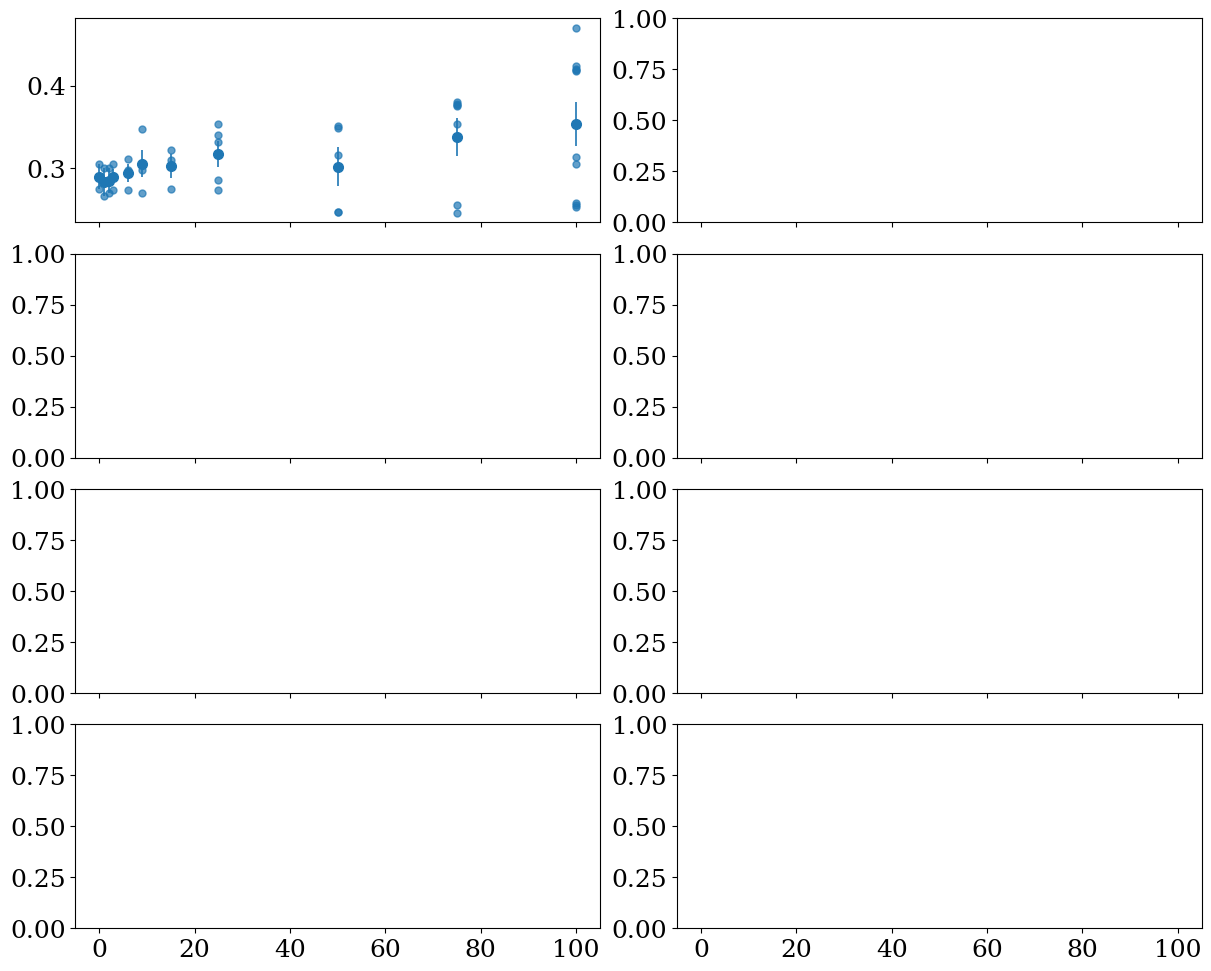

In [12]:
# ----------------------------------------------------------------------
# 1. Configuration – one entry per data set
# ----------------------------------------------------------------------
DATASETS = {
    "WT": {
        "label": "aSyn WT",
        "color": "C0",
        "marker": "o",
        "mean_marker": "o",
        "sample_asyn": {
            "BII_S9": 0.0,
            "BIV_S1": 1,
            "BIV_S2": 2,
            "BIV_S3": 3,
            "BIV_S4": 6,
            "BIV_S5": 9,
            "BIV_S6": 15,
            "BIV_S7": 25,
            "BIV_S8": 50,
            "BIV_S9": 75,
            "BIV_S10": 100,
        },
        "best_fits": best_fits_aSynWT,
    },
    "A124T": {
        "label": "aSyn A124T",
        "color": "C1",
        "marker": "s",
        "mean_marker": "s",
        "sample_asyn": {
            "BIV_S21": 1.0,
            "BIV_S22": 2.0,
            "BIV_S23": 3.0,
            "BIV_S24": 6.0,
            "BIV_S25": 9.0,
            "BIV_S26": 15.0,
            "BIV_S27": 25.0,
            "BIV_S28": 50.0,
            "BIV_S29": 75.0,
            "BIV_S30": 100.0,
        },
        "best_fits": best_fits_aSynA124T,
    },
}

# ----------------------------------------------------------------------
# 2. Helper functions (equal weighting)
# ----------------------------------------------------------------------
def linear(x, m, n):
    return m * x + n


def simple_mean(values):
    """Ordinary arithmetic mean."""
    values = np.asarray(values, dtype=float)
    if len(values) == 0:
        return np.nan
    return np.mean(values)


def simple_mean_err(values):
    """
    Standard error of the mean (SEM).
    Returns NaN when fewer than 2 points are available.
    """
    values = np.asarray(values, dtype=float)
    n = len(values)
    if n < 2:
        return np.nan
    return np.std(values, ddof=1) / np.sqrt(n)


def collect_edp_metrics(best_fits, sample_asyn):
    """Return list of records for one dataset."""
    records = []
    for sample, asyn_conc in sample_asyn.items():
        if sample not in best_fits:
            continue
        # Note the key name used in your current code
        for cfg_id, params in best_fits[sample]["ULV_spheric_asym_C4"].items():
            edp_params = params[2:8]
            edp_tot, edp_hg_tot, edp_tg, edp_hg_asym, edp_hg_tg = fit.EDP_analysis(edp_params)

            records.append({
                "sample": sample,
                "aSyn": asyn_conc,
                "EDP_tot": edp_tot,
                "EDP_hg_tot": edp_hg_tot,
                "EDP_tg": abs(edp_tg),
                "EDP_hg_asym": edp_hg_asym,
                "EDP_hg_tg": edp_hg_tg,
                "R": params[0],
                "sigma_R": params[1],
                "z_h": params[7],
            })
    return records


def aggregate_by_concentration(records):
    """Simple (unweighted) means + SEM grouped by aSyn concentration."""
    groups = defaultdict(list)
    for r in records:
        groups[r["aSyn"]].append(r)

    metrics = ["EDP_tot", "EDP_hg_tot", "EDP_tg", "EDP_hg_asym",
               "EDP_hg_tg", "z_h", "R", "sigma_R"]

    means, mean_errs = {}, {}
    concentrations = sorted(groups.keys())

    for metric in metrics:
        m_list, e_list = [], []
        for conc in concentrations:
            vals = np.array([r[metric] for r in groups[conc]])
            m_list.append(simple_mean(vals))
            e_list.append(simple_mean_err(vals))
        means[metric] = np.array(m_list)
        mean_errs[metric] = np.array(e_list)

    return concentrations, means, mean_errs


# ----------------------------------------------------------------------
# 3. Collect data for every dataset
# ----------------------------------------------------------------------
all_data = {}

for ds_name, ds in DATASETS.items():
    records = collect_edp_metrics(ds["best_fits"], ds["sample_asyn"])
    if not records:
        print(f"Warning: no records for {ds_name}")
        continue

    aSyn_all = np.array([r["aSyn"] for r in records])
    data_map = {
        "EDP_tot":     np.array([r["EDP_tot"]     for r in records]),
        "EDP_hg_tot":  np.array([r["EDP_hg_tot"]  for r in records]),
        "EDP_tg":      np.array([r["EDP_tg"]      for r in records]),
        "EDP_hg_asym": np.array([r["EDP_hg_asym"] for r in records]),
        "EDP_hg_tg":   np.array([r["EDP_hg_tg"]   for r in records]),
        "z_h":         np.array([r["z_h"]         for r in records]),
        "R":           np.array([r["R"]           for r in records]),
        "sigma_R":     np.array([r["sigma_R"]     for r in records]),
    }
    aSyn_means, means, mean_errs = aggregate_by_concentration(records)

    all_data[ds_name] = {
        "records": records,
        "aSyn_all": aSyn_all,
        "data_map": data_map,
        "aSyn_means": aSyn_means,
        "means": means,
        "mean_errs": mean_errs,
        "style": ds,
    }

# ----------------------------------------------------------------------
# 4. Plotting
# ----------------------------------------------------------------------
titles = [
    ("EDP_tot",     "(a) Total EDP integral",                     r"$(\Omega_1 + \Omega_2 + \Omega_3)$ [nm]"),
    ("EDP_hg_tot",  "(b) Lipid head groups EDP integral",         r"$(\Omega_1 + \Omega_3)$ [nm]"),
    ("EDP_tg",      "(c) Lipid tail group EDP integral",          r"$|\Omega_2|$ [nm]"),
    ("EDP_hg_asym", "(d) Lipid head groups EDP integral asymmetry", r"$\frac{|\Omega_1-\Omega_3|}{\Omega_1+\Omega_3}$"),
    ("EDP_hg_tg",   "(e) Head to tail groups EDP integral ratio", r"$\frac{\Omega_1+\Omega_3}{|\Omega_2|}$"),
    ("z_h",         "(f) Fitted head group position $z_h$",       r"$z_h$ [nm]"),
    ("R",           "(g) Fitted radius $R$",                      r"$R$ [nm]"),
    ("sigma_R",     "(h) Fitted polydispersity $\sigma_R$",       r"$\sigma_R$ [nm]"),
]

plt.rcParams.update({
    "font.family": "serif",
    "mathtext.fontset": "dejavuserif",
})

fig, axes = plt.subplots(4, 2, figsize=(12, 9.6), sharex=True, constrained_layout=True)
axes = axes.flatten()

for ax, (key, title, ylabel) in zip(axes, titles):
    for ds_name, data in all_data.items():
        style = data["style"]
        col   = style["color"]

        # individual points
        ax.plot(data["aSyn_all"], data["data_map"][key],
                ls="None", marker=style["marker"], markersize=5,
                color=col, alpha=0.7,
                label=style["label"] if key == "EDP_tot" else None)

        # unweighted means + SEM error bars
        ax.errorbar(data["aSyn_means"], data["means"][key], data["mean_errs"][key],
                    color=col, ls="None", marker=style["mean_marker"],
                    markersize=7, zorder=5, elinewidth=1.2)

        # linear fit to the means
        # (ignore NaN error bars by using only finite points)
        mask = np.isfinite(data["mean_errs"][key])
        if np.sum(mask) >= 2:
            popt, pcov = curve_fit(
                linear,
                data["aSyn_means"][mask], data["means"][key][mask],
                sigma=data["mean_errs"][key][mask],
                maxfev=20000, p0=[0.0, 0.0]
            )
            perr = np.sqrt(np.diag(pcov))
            print(f"{ds_name} – {key}:  m = {popt[0]:.4g} ± {perr[0]:.4g},  "
                  f"n = {popt[1]:.4g} ± {perr[1]:.4g}")

            ax.plot(data["aSyn_means"], linear(data["aSyn_means"], *popt),
                    color=col, alpha=0.6, linewidth=1.0)

    ax.set_title(title, fontsize=14)
    ax.set_ylabel(ylabel, fontsize=14)
    ax.grid(True)

axes[0].legend(fontsize=11, frameon=True)

for ax in axes[-2:]:
    ax.set_xlabel("aSyn concentration [µM]", fontsize=14)

# ----------------------------------------------------------------------
# 5. Save / show
# ----------------------------------------------------------------------
# target_folder = Path("figures")
# target_folder.mkdir(exist_ok=True)
# fig.savefig(target_folder / "EDP_metrics_spherical_WT_vs_A124T.png",
#             dpi=600, bbox_inches="tight")
plt.show()

<>:265: SyntaxWarning: "\s" is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\s"? A raw string is also an option.
<>:265: SyntaxWarning: "\s" is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\s"? A raw string is also an option.
C:\Users\riko05\AppData\Local\Temp\ipykernel_24512\2200395435.py:265: SyntaxWarning: "\s" is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\s"? A raw string is also an option.
  "(h) Fitted polydispersity $\sigma_R$",


WT – EDP_tot: m = 0.0006506 ± 0.0001035, n = 0.2889 ± 0.002319
A124T – EDP_tot: m = 0.0006605 ± 8.692e-05, n = 0.2854 ± 0.001553
WT – EDP_hg_tot: m = 0.0005092 ± 0.0004775, n = 1.813 ± 0.008708
A124T – EDP_hg_tot: m = 0.0004704 ± 0.000258, n = 1.797 ± 0.003414
WT – EDP_tg: m = -0.0001969 ± 0.0002104, n = 1.52 ± 0.006592
A124T – EDP_tg: m = -1.534e-05 ± 7.465e-05, n = 1.508 ± 0.003621
WT – EDP_hg_asym: m = 0.002009 ± 0.0001063, n = 0.1766 ± 0.005028
A124T – EDP_hg_asym: m = 0.00143 ± 0.0001746, n = 0.184 ± 0.006039
WT – EDP_hg_tg: m = 0.0004211 ± 5.552e-05, n = 1.189 ± 0.001195
A124T – EDP_hg_tg: m = 0.0004634 ± 5.732e-05, n = 1.189 ± 0.001064
WT – z_h: m = -0.0004903 ± 0.0001734, n = 1.905 ± 0.00237
A124T – z_h: m = -0.0003048 ± 3.87e-05, n = 1.905 ± 0.001552
WT – R: m = 0.0219 ± 0.01116, n = 13.43 ± 0.5669
A124T – R: m = -0.01013 ± 0.004629, n = 13.05 ± 0.1979
WT – sigma_R: m = 0.02871 ± 0.003278, n = 3.792 ± 0.2354
A124T – sigma_R: m = 0.02472 ± 0.001596, n = 3.538 ± 0.1595


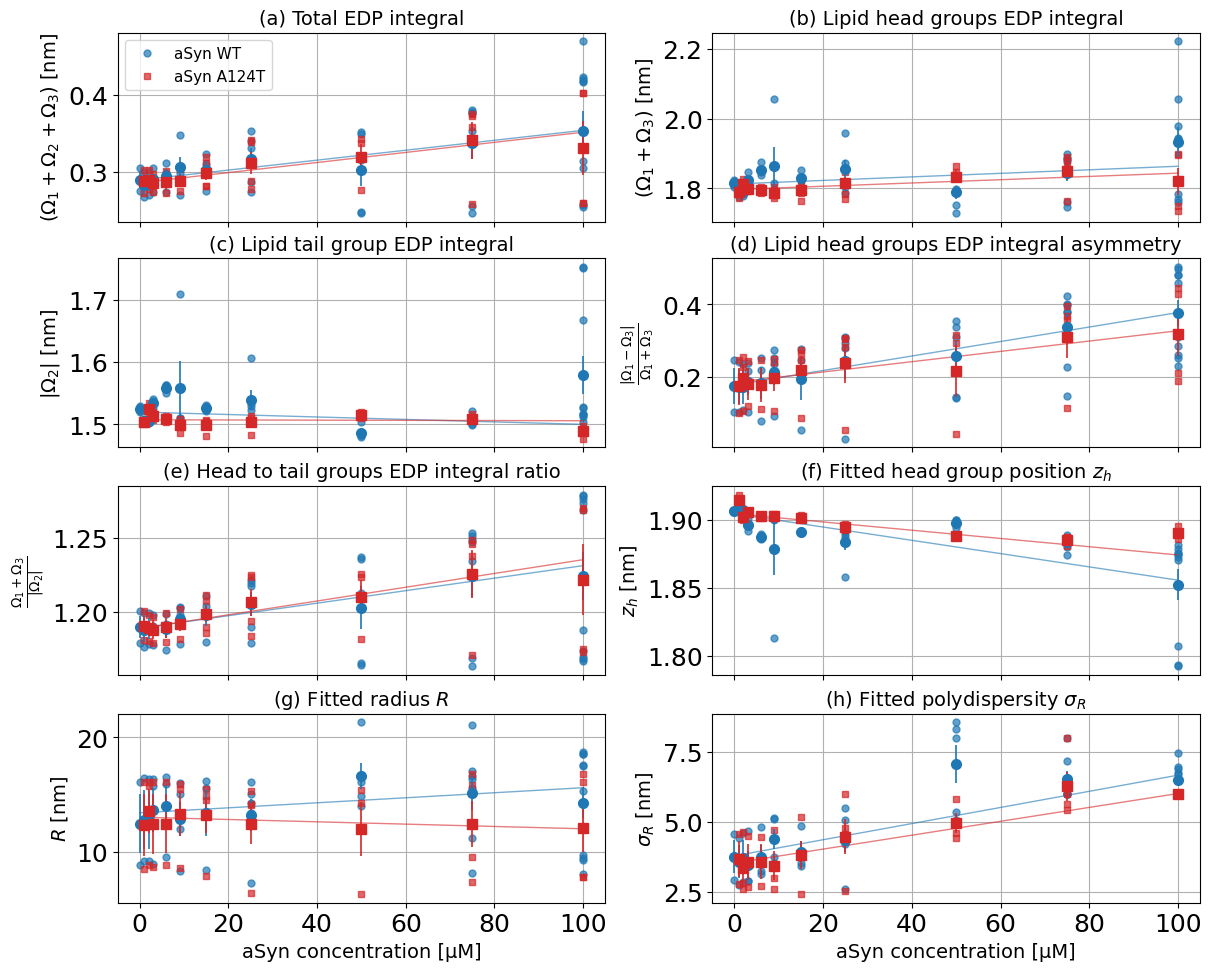

In [3]:
from collections import defaultdict

import numpy as np
import matplotlib.pyplot as plt
from scipy.optimize import curve_fit


# ============================================================================
# Configuration
# ============================================================================

DATASETS = {
    "WT": {
        "label": "aSyn WT",
        "color": "C0",
        "marker": "o",
        "best_fits": best_fits_aSynWT,
        "sample_asyn": {
            "BII_S9": 0.0,
            "BIV_S1": 1.0,
            "BIV_S2": 2.0,
            "BIV_S3": 3.0,
            "BIV_S4": 6.0,
            "BIV_S5": 9.0,
            "BIV_S6": 15.0,
            "BIV_S7": 25.0,
            "BIV_S8": 50.0,
            "BIV_S9": 75.0,
            "BIV_S10": 100.0,
        },
    },

    "A124T": {
        "label": "aSyn A124T",
        "color": "C3",
        "marker": "s",
        "best_fits": best_fits_aSynA124T,
        "sample_asyn": {
            "BIV_S21": 1.0,
            "BIV_S22": 2.0,
            "BIV_S23": 3.0,
            "BIV_S24": 6.0,
            "BIV_S25": 9.0,
            "BIV_S26": 15.0,
            "BIV_S27": 25.0,
            "BIV_S28": 50.0,
            "BIV_S29": 75.0,
            "BIV_S30": 100.0,
        },
    },
}


# ============================================================================
# General helpers
# ============================================================================

def linear(x, m, n):
    return m * x + n


def mean_and_sem(values):
    """
    Ordinary arithmetic mean and standard error of the mean.

    Returns
    -------
    mean : float
    sem : float
        NaN if fewer than two values are available.
    """
    values = np.asarray(values, dtype=float)

    if values.size == 0:
        return np.nan, np.nan

    mean = np.mean(values)

    if values.size < 2:
        return mean, np.nan

    sem = np.std(values, ddof=1) / np.sqrt(values.size)
    return mean, sem


# ============================================================================
# Extract EDP quantities from one dataset
# ============================================================================

def collect_metrics(best_fits, sample_asyn):
    """
    Extract EDP quantities and fitted structural parameters.

    Every configuration is kept as an individual data point. No chi2
    weighting is performed anywhere in this step.
    """
    records = []

    for sample, asyn_conc in sample_asyn.items():
        fit_configs = best_fits[sample].get("ULV_spheric_asym_C4", {})

        for config_id, params in fit_configs.items():

            edp_params = params[2:8]

            (
                edp_tot,
                edp_hg_tot,
                edp_tg,
                edp_hg_asym,
                edp_hg_tg,
            ) = fit.EDP_analysis(edp_params)

            records.append({
                "sample": sample,
                "config": config_id,
                "aSyn": asyn_conc,

                "EDP_tot": edp_tot,
                "EDP_hg_tot": edp_hg_tot,
                "EDP_tg": abs(edp_tg),
                "EDP_hg_asym": edp_hg_asym,
                "EDP_hg_tg": edp_hg_tg,

                "R": params[0],
                "sigma_R": params[1],
                "z_h": params[7],
            })

    return records


# ============================================================================
# Group configurations by aSyn concentration and calculate mean + SEM
# ============================================================================

METRICS = (
    "EDP_tot",
    "EDP_hg_tot",
    "EDP_tg",
    "EDP_hg_asym",
    "EDP_hg_tg",
    "z_h",
    "R",
    "sigma_R",
)


def aggregate_by_concentration(records):
    """
    Calculate ordinary (unweighted) mean and SEM for each concentration.
    """
    groups = defaultdict(list)

    for record in records:
        groups[record["aSyn"]].append(record)

    concentrations = np.array(sorted(groups), dtype=float)
    means = {}
    sems = {}

    for metric in METRICS:

        metric_means = []
        metric_sems = []

        for concentration in concentrations:
            
            values = [
                record[metric]
                for record in groups[concentration]
            ]
            

            mean, sem = np.mean(values), np.std(values) / np.sqrt(len(values))

            metric_means.append(mean)
            metric_sems.append(sem)
            # if concentration == 1:
            #     print(f"Metric {metric}, concentration {concentration}")
            #     print(mean, sem, values)

        means[metric] = np.asarray(metric_means)
        sems[metric] = np.asarray(metric_sems)
        # print(f"Metric {metric}: means = {means[metric]}, sems = {sems[metric]}")

    return concentrations, means, sems


# ============================================================================
# Prepare all datasets
# ============================================================================

all_data = {}

for dataset_name, dataset in DATASETS.items():

    records = collect_metrics(
        dataset["best_fits"],
        dataset["sample_asyn"],
    )

    concentrations, means, sems = aggregate_by_concentration(records)

    all_data[dataset_name] = {
        "records": records,
        "style": dataset,

        # Individual points
        "aSyn_all": np.array([r["aSyn"] for r in records]),
        "data": {
            metric: np.array([r[metric] for r in records])
            for metric in METRICS
        },

        # Mean values
        "aSyn_means": concentrations,
        "means": means,
        "sems": sems,
    }


# ============================================================================
# Plot configuration
# ============================================================================

PLOT_INFO = [
    (
        "EDP_tot",
        "(a) Total EDP integral",
        r"$(\Omega_1 + \Omega_2 + \Omega_3)$ [nm]",
    ),
    (
        "EDP_hg_tot",
        "(b) Lipid head groups EDP integral",
        r"$(\Omega_1 + \Omega_3)$ [nm]",
    ),
    (
        "EDP_tg",
        "(c) Lipid tail group EDP integral",
        r"$|\Omega_2|$ [nm]",
    ),
    (
        "EDP_hg_asym",
        "(d) Lipid head groups EDP integral asymmetry",
        r"$\frac{|\Omega_1-\Omega_3|}{\Omega_1+\Omega_3}$",
    ),
    (
        "EDP_hg_tg",
        "(e) Head to tail groups EDP integral ratio",
        r"$\frac{\Omega_1+\Omega_3}{|\Omega_2|}$",
    ),
    (
        "z_h",
        "(f) Fitted head group position $z_h$",
        r"$z_h$ [nm]",
    ),
    (
        "R",
        "(g) Fitted radius $R$",
        r"$R$ [nm]",
    ),
    (
        "sigma_R",
        "(h) Fitted polydispersity $\sigma_R$",
        r"$\sigma_R$ [nm]",
    ),
]


# ============================================================================
# Plot
# ============================================================================

# plt.rcParams.update({
#     "font.family": "serif",
#     "mathtext.fontset": "dejavuserif",
# })

fig, axes = plt.subplots(
    nrows=4,
    ncols=2,
    figsize=(12, 9.6),
    sharex=True,
    constrained_layout=True,
)

axes = axes.flatten()


for ax, (metric, title, ylabel) in zip(axes, PLOT_INFO):

    for dataset_name, dataset in all_data.items():

        style = dataset["style"]
        color = style["color"]
        marker = style["marker"]

        # ------------------------------------------------------------------
        # Individual fit results
        # ------------------------------------------------------------------
        # if metric == "EDP_tot":
        #     print(dataset["aSyn_all"])
        ax.plot(
            dataset["aSyn_all"],
            dataset["data"][metric],
            ls="None",
            marker=marker,
            markersize=5,
            color=color,
            alpha=0.7,
            label=style["label"],
        )

        # ------------------------------------------------------------------
        # Mean ± SEM
        # ------------------------------------------------------------------

        x_mean = dataset["aSyn_means"]
        y_mean = dataset["means"][metric]
        y_sem = dataset["sems"][metric]

        ax.errorbar(
            x_mean,
            y_mean,
            yerr=y_sem,
            ls="None",
            marker=marker,
            markersize=7,
            color=color,
            elinewidth=1.2,
            capsize=0,
            zorder=5,
        )

        # ------------------------------------------------------------------
        # Linear fit
        #
        # The means themselves are unweighted.
        # The regression uses the SEM as uncertainty weighting.
        # ------------------------------------------------------------------

        valid = (
            np.isfinite(x_mean)
            & np.isfinite(y_mean)
            & np.isfinite(y_sem)
            & (y_sem > 0)
        )


        x_fit_data = x_mean[valid]
        y_fit_data = y_mean[valid]
        y_fit_err = y_sem[valid]

        popt, pcov = curve_fit(
            linear,
            x_fit_data,
            y_fit_data,
            sigma=y_fit_err,
            p0=[0.0, 0.0],
            maxfev=20000,
        )

        parameter_errors = np.sqrt(np.diag(pcov))

        print(
            f"{dataset_name} – {metric}: "
            f"m = {popt[0]:.4g} ± {parameter_errors[0]:.4g}, "
            f"n = {popt[1]:.4g} ± {parameter_errors[1]:.4g}"
        )

        # Smooth fit line
        x_line = np.linspace(
            x_fit_data.min(),
            x_fit_data.max(),
            200,
        )

        ax.plot(
            x_line,
            linear(x_line, *popt),
            color=color,
            alpha=0.6,
            linewidth=1.0,
        )

    # ----------------------------------------------------------------------
    # Axes formatting
    # ----------------------------------------------------------------------

    ax.set_title(title, fontsize=14)
    ax.set_ylabel(ylabel, fontsize=14)
    ax.grid(True)


# ============================================================================
# Legend and common x-axis labels
# ============================================================================

axes[0].legend(
    fontsize=11,
    frameon=True,
)

for ax in axes[-2:]:
    ax.set_xlabel(
        "aSyn concentration [µM]",
        fontsize=14,
    )


# ============================================================================
# Save / show
# ============================================================================

target_folder = Path("C:/Users/riko05/Documents/8. SoSe 26/Code/BM29_data_and_analysis_2026/analysis_BM29_July2026/Results_and_Figures/Aug27/Plot_WT_A124T")
fig.savefig(
    target_folder / "EDP_metrics_spherical_WT_vs_A124T_stats.png",
    dpi=600,
    bbox_inches="tight",
)

plt.show()

<>:110: SyntaxWarning: "\s" is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\s"? A raw string is also an option.
<>:110: SyntaxWarning: "\s" is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\s"? A raw string is also an option.
C:\Users\riko05\AppData\Local\Temp\ipykernel_12776\95980500.py:110: SyntaxWarning: "\s" is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\s"? A raw string is also an option.
  "(h) Fitted polydispersity $\sigma_R$",


Dataset WT, metric EDP_tot: y_mean = [0.28950693 0.28289596 0.28465059 0.28977275 0.29390824 0.30532137
 0.30258201 0.31675845 0.30175032 0.33779622 0.35356605]
WT – EDP_tot: m = 0.0006368 ± 9.699e-05, n = 0.2895 ± 0.002497
    R² = 0.8585, χ² = 2.0737, χ²_red = 0.2304, F = 54.5828, p = 4.156e-05
Dataset A124T, metric EDP_tot: y_mean = [0.2872703  0.28863753 0.28494039 0.286253   0.2879778  0.2978369
 0.31102212 0.31869093 0.34088748 0.33080219]
A124T – EDP_tot: m = 0.0006572 ± 8.606e-05, n = 0.2857 ± 0.001645
    R² = 0.8488, χ² = 0.9756, χ²_red = 0.1219, F = 44.9100, p = 0.0001525
Dataset WT, metric EDP_hg_tot: y_mean = [1.81418867 1.78829872 1.79063464 1.82461717 1.85308715 1.86303167
 1.82930835 1.85573532 1.78835589 1.84495393 1.93267924]
WT – EDP_hg_tot: m = 0.0004606 ± 0.0004291, n = 1.815 ± 0.009268
    R² = 0.2741, χ² = 29.2529, χ²_red = 3.2503, F = 3.3979, p = 0.09839
Dataset A124T, metric EDP_hg_tot: y_mean = [1.79101145 1.81293068 1.79834928 1.79484829 1.78709286 1.79625282

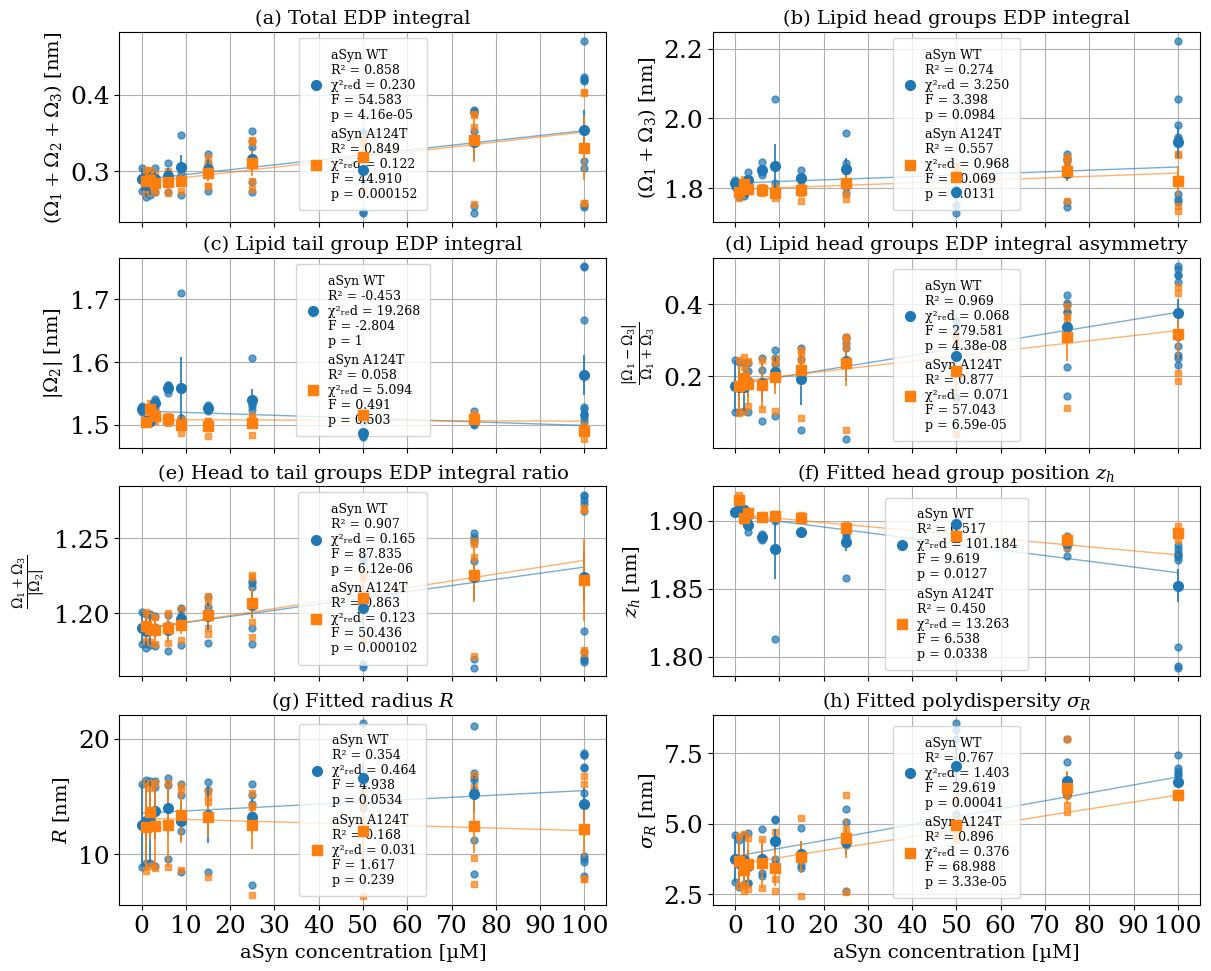

In [ ]:
from collections import defaultdict

import numpy as np
import matplotlib.pyplot as plt
from scipy.optimize import curve_fit
from scipy.stats import f
from matplotlib.lines import Line2D


# =============================================================================
# Configuration
# =============================================================================

DATASETS = {
    "WT": {
        "label": "aSyn WT",
        "color": "C0",
        "marker": "o",
        "best_fits": best_fits_aSynWT,
        "sample_asyn": {
            "BII_S9": 0.0,
            "BIV_S1": 1.0,
            "BIV_S2": 2.0,
            "BIV_S3": 3.0,
            "BIV_S4": 6.0,
            "BIV_S5": 9.0,
            "BIV_S6": 15.0,
            "BIV_S7": 25.0,
            "BIV_S8": 50.0,
            "BIV_S9": 75.0,
            "BIV_S10": 100.0,
        },
    },

    "A124T": {
        "label": "aSyn A124T",
        "color": "C1",
        "marker": "s",
        "best_fits": best_fits_aSynA124T,
        "sample_asyn": {
            "BIV_S21": 1.0,
            "BIV_S22": 2.0,
            "BIV_S23": 3.0,
            "BIV_S24": 6.0,
            "BIV_S25": 9.0,
            "BIV_S26": 15.0,
            "BIV_S27": 25.0,
            "BIV_S28": 50.0,
            "BIV_S29": 75.0,
            "BIV_S30": 100.0,
        },
    },
}


# =============================================================================
# Metrics
# =============================================================================

METRICS = (
    "EDP_tot",
    "EDP_hg_tot",
    "EDP_tg",
    "EDP_hg_asym",
    "EDP_hg_tg",
    "z_h",
    "R",
    "sigma_R",
)


PLOT_INFO = [
    (
        "EDP_tot",
        "(a) Total EDP integral",
        r"$(\Omega_1 + \Omega_2 + \Omega_3)$ [nm]",
    ),
    (
        "EDP_hg_tot",
        "(b) Lipid head groups EDP integral",
        r"$(\Omega_1 + \Omega_3)$ [nm]",
    ),
    (
        "EDP_tg",
        "(c) Lipid tail group EDP integral",
        r"$|\Omega_2|$ [nm]",
    ),
    (
        "EDP_hg_asym",
        "(d) Lipid head groups EDP integral asymmetry",
        r"$\frac{|\Omega_1-\Omega_3|}{\Omega_1+\Omega_3}$",
    ),
    (
        "EDP_hg_tg",
        "(e) Head to tail groups EDP integral ratio",
        r"$\frac{\Omega_1+\Omega_3}{|\Omega_2|}$",
    ),
    (
        "z_h",
        "(f) Fitted head group position $z_h$",
        r"$z_h$ [nm]",
    ),
    (
        "R",
        "(g) Fitted radius $R$",
        r"$R$ [nm]",
    ),
    (
        "sigma_R",
        "(h) Fitted polydispersity $\sigma_R$",
        r"$\sigma_R$ [nm]",
    ),
]


# =============================================================================
# Helper functions
# =============================================================================

def linear(x, m, n):
    return m * x + n


def mean_and_sem(values):
    """
    Calculate ordinary arithmetic mean and SEM.
    """
    values = np.asarray(values, dtype=float)

    if values.size == 0:
        return np.nan, np.nan

    mean = np.mean(values)

    if values.size < 2:
        return mean, np.nan

    sem = np.std(values, ddof=1) / np.sqrt(values.size)

    return mean, sem


def collect_metrics(best_fits, sample_asyn):
    """
    Extract all individual fit configurations.

    No chi2 weighting is applied.
    """
    records = []

    for sample, asyn_conc in sample_asyn.items():

        if sample not in best_fits:
            continue

        fit_configs = best_fits[sample].get(
            "ULV_spheric_asym_C4",
            {}
        )

        for config_id, params in fit_configs.items():

            edp_params = params[2:8]

            (
                edp_tot,
                edp_hg_tot,
                edp_tg,
                edp_hg_asym,
                edp_hg_tg,
            ) = fit.EDP_analysis(edp_params)

            records.append({
                "sample": sample,
                "config": config_id,
                "aSyn": asyn_conc,

                "EDP_tot": edp_tot,
                "EDP_hg_tot": edp_hg_tot,
                "EDP_tg": abs(edp_tg),
                "EDP_hg_asym": edp_hg_asym,
                "EDP_hg_tg": edp_hg_tg,

                "R": params[0],
                "sigma_R": params[1],
                "z_h": params[7],
            })

    return records


def aggregate_by_concentration(records):
    """
    Group individual fits by aSyn concentration and calculate
    ordinary mean + SEM.
    """
    groups = defaultdict(list)

    for record in records:
        groups[record["aSyn"]].append(record)

    concentrations = np.array(
        sorted(groups.keys()),
        dtype=float,
    )

    means = {}
    sems = {}

    for metric in METRICS:

        metric_means = []
        metric_sems = []

        for concentration in concentrations:

            values = [
                record[metric]
                for record in groups[concentration]
            ]

            mean, sem = mean_and_sem(values)

            metric_means.append(mean)
            metric_sems.append(sem)

        means[metric] = np.asarray(metric_means)
        sems[metric] = np.asarray(metric_sems)

    return concentrations, means, sems


def calculate_linear_fit_statistics(x, y, yerr):
    """
    Perform linear fit and calculate:

        - slope and intercept
        - parameter uncertainties
        - R²
        - chi²
        - reduced chi²
        - F statistic
        - F-test p value
        - residual standard deviation

    The linear fit is weighted by yerr.
    The F test and R² are calculated exactly as in the reference code.
    """

    x = np.asarray(x, dtype=float)
    y = np.asarray(y, dtype=float)
    yerr = np.asarray(yerr, dtype=float)

    valid = (
        np.isfinite(x)
        & np.isfinite(y)
        & np.isfinite(yerr)
        & (yerr > 0)
    )

    x = x[valid]
    y = y[valid]
    yerr = yerr[valid]

    # -------------------------------------------------------------------------
    # Linear fit
    # -------------------------------------------------------------------------

    popt, pcov = curve_fit(
        linear,
        x,
        y,
        sigma=yerr,
        p0=[0.0, 0.0],
        maxfev=20000,
    )

    perr = np.sqrt(np.diag(pcov))

    # -------------------------------------------------------------------------
    # Predictions and residuals
    # -------------------------------------------------------------------------

    y_pred = linear(x, *popt)
    residuals = y - y_pred

    # -------------------------------------------------------------------------
    # R²
    # -------------------------------------------------------------------------

    ss_res = np.sum(residuals**2)
    ss_tot = np.sum((y - np.mean(y))**2)
    r_squared = 1.0 - ss_res / ss_tot

    # -------------------------------------------------------------------------
    # Degrees of freedom
    #
    # Two fitted parameters: slope + intercept
    # -------------------------------------------------------------------------

    dof = len(y) - len(popt)

    # ---------------------------------------------------------------------
    # Chi²
    # ---------------------------------------------------------------------

    chi_squared = np.sum(
        (residuals / yerr) ** 2
    )

    reduced_chi_squared = chi_squared / dof

    # ---------------------------------------------------------------------
    # Residual standard deviation
    # ---------------------------------------------------------------------

    residual_std = np.sqrt(ss_res / dof)

    # ---------------------------------------------------------------------
    # F test
    #
    # Same definition as in the reference code:
    #
    # F = (SS_tot - SS_res) / (SS_res / dof)
    # ---------------------------------------------------------------------
    f_stat = (
        (ss_tot - ss_res)
        / (ss_res / dof)
    )

    p_value = f.sf(
        f_stat,
        1,
        dof,
    )



    return {
        "popt": popt,
        "pcov": pcov,
        "perr": perr,

        "r_squared": r_squared,

        "chi_squared": chi_squared,
        "reduced_chi_squared": reduced_chi_squared,

        "f_stat": f_stat,
        "p_value": p_value,

        "residual_std": residual_std,

        "dof": dof,

        "x": x,
        "y": y,
        "yerr": yerr,
    }


def make_legend_handle(color, marker, label):
    """
    Create a clean legend handle for one dataset.
    """
    return Line2D(
        [0],
        [0],
        linestyle="None",
        marker=marker,
        markersize=7,
        color=color,
        label=label,
    )


def format_statistics_label(dataset_label, statistics):
    """
    Build the multiline legend entry containing the dataset name
    and all fit statistics.
    """

    r2 = statistics["r_squared"]
    red_chi2 = statistics["reduced_chi_squared"]
    f_stat = statistics["f_stat"]
    p_value = statistics["p_value"]

    return (
        f"{dataset_label}\n"
        f"R² = {r2:.3f}\n"
        f"χ²ᵣₑd = {red_chi2:.3f}\n"
        f"F = {f_stat:.3f}\n"
        f"p = {p_value:.3g}"
    )


# =============================================================================
# Collect all data
# =============================================================================

all_data = {}

for dataset_name, dataset in DATASETS.items():

    records = collect_metrics(
        dataset["best_fits"],
        dataset["sample_asyn"],
    )

    if not records:
        print(
            f"Warning: no records found for {dataset_name}"
        )
        continue

    concentrations, means, sems = aggregate_by_concentration(
        records
    )

    all_data[dataset_name] = {
        "records": records,
        "style": dataset,

        # Individual points
        "aSyn_all": np.array(
            [record["aSyn"] for record in records]
        ),

        "data": {
            metric: np.array(
                [record[metric] for record in records]
            )
            for metric in METRICS
        },

        # Means and SEMs
        "aSyn_means": concentrations,
        "means": means,
        "sems": sems,
    }


# =============================================================================
# Plot
# =============================================================================

plt.rcParams.update({
    "font.family": "serif",
    "mathtext.fontset": "dejavuserif",
})

fig, axes = plt.subplots(
    nrows=4,
    ncols=2,
    figsize=(12, 9.6),
    sharex=True,
    constrained_layout=True,
)

axes = axes.flatten()


# Store statistics for optional later use
fit_statistics = {}


for ax, (metric, title, ylabel) in zip(
    axes,
    PLOT_INFO,
):

    fit_statistics[metric] = {}

    legend_handles = []

    for dataset_name, dataset in all_data.items():

        style = dataset["style"]
        color = style["color"]
        marker = style["marker"]
        label = style["label"]

        # =====================================================================
        # Individual fit configurations
        # =====================================================================

        ax.plot(
            dataset["aSyn_all"],
            dataset["data"][metric],

            linestyle="None",
            marker=marker,
            markersize=5,

            color=color,
            alpha=0.7,
        )

        # =====================================================================
        # Mean ± SEM
        # =====================================================================

        x_mean = dataset["aSyn_means"]
        y_mean = dataset["means"][metric]
        y_sem = dataset["sems"][metric]

        ax.errorbar(
            x_mean,
            y_mean,
            yerr=y_sem,

            linestyle="None",
            marker=marker,
            markersize=7,

            color=color,
            elinewidth=1.2,
            capsize=0,

            zorder=5,
        )

        # =====================================================================
        # Linear fit + statistics
        # =====================================================================

        statistics = calculate_linear_fit_statistics(
            x_mean,
            y_mean,
            y_sem,
        )

        if statistics is None:
            print(
                f"{dataset_name} – {metric}: "
                "not enough valid points for linear fit."
            )
            continue

        fit_statistics[metric][dataset_name] = statistics

        popt = statistics["popt"]
        perr = statistics["perr"]

        # ---------------------------------------------------------------------
        # Print results
        # ---------------------------------------------------------------------

        print(
            f"{dataset_name} – {metric}: "
            f"m = {popt[0]:.4g} ± {perr[0]:.4g}, "
            f"n = {popt[1]:.4g} ± {perr[1]:.4g}"
        )

        print(
            f"    R² = {statistics['r_squared']:.4f}, "
            f"χ² = {statistics['chi_squared']:.4f}, "
            f"χ²_red = {statistics['reduced_chi_squared']:.4f}, "
            f"F = {statistics['f_stat']:.4f}, "
            f"p = {statistics['p_value']:.4g}"
        )

        # ---------------------------------------------------------------------
        # Smooth fit line
        # ---------------------------------------------------------------------

        x_valid = statistics["x"]

        x_line = np.linspace(
            x_valid.min(),
            x_valid.max(),
            200,
        )

        ax.plot(
            x_line,
            linear(x_line, *popt),

            color=color,
            alpha=0.6,
            linewidth=1.0,
        )

        # ---------------------------------------------------------------------
        # Legend entry containing dataset + statistics
        # ---------------------------------------------------------------------

        legend_label = format_statistics_label(
            label,
            statistics,
        )

        legend_handles.append(
            make_legend_handle(
                color,
                marker,
                legend_label,
            )
        )

    # =========================================================================
    # Axis formatting
    # =========================================================================

    ax.set_title(
        title,
        fontsize=14,
    )

    ax.set_ylabel(
        ylabel,
        fontsize=14,
    )

    ax.grid(True)

    ax.set_xticks(
        np.arange(0, 105, 10)
    )

    # =========================================================================
    # Subplot-specific legend
    # =========================================================================

    if legend_handles:
        ax.legend(
            handles=legend_handles,
            loc="best",
            fontsize=9,
            frameon=True,
            handlelength=1.2,
            handletextpad=0.6,
            borderpad=0.8,
        )


# =============================================================================
# Common x-axis labels
# =============================================================================

for ax in axes[-2:]:
    ax.set_xlabel(
        "aSyn concentration [µM]",
        fontsize=14,
    )


# =============================================================================
# Save / show
# =============================================================================

# target_folder = Path("figures")
# fig.savefig(
#     target_folder / "EDP_metrics_spherical_WT_vs_A124T_stats.png",
#     dpi=600,
#     bbox_inches="tight",
# )

# fig.savefig(
#     target_folder / "EDP_metrics_spherical_WT_vs_A124T_stats.svg",
#     bbox_inches="tight",
# )

plt.show()